In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA,KernelPCA
from sklearn.model_selection import train_test_split

from sklearn.mixture import GaussianMixture

from sklearn.metrics import (
    accuracy_score, 
    precision_score, 
    recall_score, 
    f1_score, 
    classification_report, 
    confusion_matrix, 
    roc_auc_score, 
    roc_curve
)

In [3]:
# Part 1: Data Preprocessing
# 1. Loading the Dataset:
# o Load the Activity Recognition dataset into a pandas DataFrame.

df = pd.read_csv('Activity_data.csv')

# o Display the first few rows and check for any missing values.

df.head(100)

# o Handle missing values if necessary.



,Time,frontal_axis_Acceleration,vertical_axis+_Acceleration,lateral_axis_Acceleration,Antenna_ID_Sensor,RSSI,Phase,Frequency,Activity
0,0.00,-0.232160,0.215880,-1.18820,2,-48.5,2.744300,920.75,3
1,0.25,-0.056282,0.043636,-1.14260,2,-50.0,2.365400,921.75,3
2,0.50,0.143050,0.296270,-1.33640,3,-59.5,0.207090,922.25,3
3,0.75,0.318930,0.284780,-0.92593,2,-51.0,0.415710,923.25,3
4,1.05,0.412730,0.135500,-1.02860,2,-44.5,4.454700,920.25,3
...,...,...,...,...,...,...,...,...,...
95,34.50,0.236850,0.169950,-1.00570,2,-52.0,1.995700,921.75,3
96,35.00,0.307210,0.146980,-0.98294,2,-50.5,2.569400,920.25,3
97,35.25,0.049247,0.261820,-1.08560,3,-62.0,0.056757,920.25,3
98,35.75,0.060972,0.261820,-1.08560,3,-64.5,4.292100,924.75,3


In [4]:
data = df.iloc[:,1:-1].to_numpy()
label = df.iloc[:,-1].to_numpy()

print(data.shape)

(75128, 7)


In [5]:
# 2. Train-Test Split:
# In this part, you will apply several classifiers to the entire dataset without any dimensionality reduction.

# o Split the dataset into training and testing sets.
# o Use an 80/20 split, where 80% of the data is used for training and 20% for testing.

x_train, x_test, y_train, y_test = train_test_split(data, label, test_size=0.2)

print(x_train.shape)
print(x_test.shape)

(60102, 7)
(15026, 7)


In [5]:
# Part 2: Classification on the Entire Dataset
# In this part, you will apply several classifiers to the entire dataset without any dimensionality reduction.

# 1. Bayesian Classifier (from scratch):

# ▪ Implement a Bayesian classifier by calculating the prior probabilities and
#   modeling the likelihood with a Gaussian distribution.

total_count = len(df)

def bayes_train(data, label):
    classes = np.unique(label)
    n = len(label)
    model={}

    for c in classes:
        D_i = data[label==c]
        n_i = len(D_i)
        pci = n_i/n

        # compute mean of D_i
        mu_i = np.mean(D_i, axis=0)

        # center D_i
        Z_i = D_i - mu_i

        # Compute covariance Matrix
        sigma_i = (Z_i.T@Z_i)/n_i

        # save these in Dictionary
        model[c] = {"prior":pci, "mean":mu_i,"covariance":sigma_i}
    return model

def gaussian_fun(x,mu,sigma):
    d = len(mu)
    diff = x - mu
    sigma_inv = np.linalg.inv(sigma)
    det = np.linalg.det(sigma)
    f = (1/(np.sqrt(2*np.pi)**d * det))*np.exp(-0.5*diff.T@sigma_inv@diff)
    return f

def bayes_predict(X_test, model):
    predictions=[]
    for x in X_test:
        scores = {}
        for c,parameters in model.items():
            prior = parameters["prior"]
            mu = parameters["mean"]
            sigma = parameters["covariance"]

            # compute the gaussian
            likelihood = gaussian_fun(x,mu,sigma)
            scores[c] = likelihood*prior

        prediction_class = max(scores,key = scores.get)
        predictions.append(prediction_class)
    
    return np.array(predictions)


# ▪ Use Bayes' Theorem to compute the posterior probability for each class and classify the test data.
model = bayes_train(x_train, y_train)
y_pred_bayes = bayes_predict(x_test, model)


In [34]:
from sklearn.svm import SVC
# 2. Other Classifiers (using scikit-learn): Apply the following classifiers from scikit-learn:

#      ▪ Support Vector Machine (SVM):
#           ▪ Use both Linear SVM and Kernel SVM (RBF and Polynomial kernels).

svm = SVC()
svm.fit(x_train, y_train)
y_pred_svm = svm.predict(x_test)


In [55]:
svm_poly = SVC(kernel='poly')
svm_poly.fit(x_train, y_train)
y_pred_svm_poly = svm_poly.predict(x_test)

In [59]:
from sklearn.svm import LinearSVC

svm_linear = LinearSVC()
svm_linear.fit(x_train, y_train)
y_pred_svm_linear = svm_linear.predict(x_test)

In [6]:
from sklearn.neighbors import KNeighborsClassifier
#      ▪ k-Nearest Neighbors (KNN):
#           ▪ Experiment with different values for k.

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(x_train, y_train)
y_pred_knn = knn.predict(x_test)


In [7]:
from sklearn.datasets import load_iris
from sklearn.naive_bayes import GaussianNB
#      ▪ Naive Bayes:
#           ▪ Implement Gaussian Naive Bayes using GaussianNB.

gnb = GaussianNB()
y_pred_gnb = gnb.fit(x_train, y_train).predict(x_test)
print("Number of mislabeled points out of a total %d points : %d" % (x_test.shape[0], (y_test != y_pred_gnb).sum()))


Number of mislabeled points out of a total 15026 points : 829


In [8]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
#      ▪ Linear Discriminant Analysis (LDA):
#           ▪ Use LinearDiscriminantAnalysis.

lda = LinearDiscriminantAnalysis()
lda.fit(x_train, y_train)
print(lda.predict(x_test))
y_pred_lda = lda.predict(x_test)



[3 3 3 ... 3 3 3]


In [75]:
#      ▪ Kernel Discriminant Analysis (KDA):
#           ▪ Implement KDA using different kernels (RBF, Polynomial).
from sklearn.pipeline import Pipeline
from sklearn.kernel_approximation import Nystroem
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# I am using Nystroem because creating a kernel directly causes a memory overload error/crash

kda_safeguard_pipeline = Pipeline([
    ('kernel_approx', Nystroem(kernel='rbf', gamma=0.1, n_components=1000,)),
    ('lda', LinearDiscriminantAnalysis())
])


kda_safeguard_pipeline.fit(x_train, y_train)
y_pred_kda = kda_safeguard_pipeline.predict(x_test)

print("--- Core Classification Metrics for KDA (RBF) ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_kda):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_kda, average='weighted'):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_kda, average='weighted'):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_kda, average='weighted'):.4f}")


--- Core Classification Metrics for KDA (RBF) ---
Accuracy:  0.9707
Precision: 0.9694
Recall:    0.9707
F1-Score:  0.9694


In [74]:
kda_safeguard_pipeline = Pipeline([
    ('kernel_approx', Nystroem(kernel='poly', gamma=0.1, n_components=1000,)),
    ('lda', LinearDiscriminantAnalysis())
])


kda_safeguard_pipeline.fit(x_train, y_train)
y_pred_kda_poly = kda_safeguard_pipeline.predict(x_test)

print("--- Core Classification Metrics for KDA (Poly) ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_kda_poly):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_kda_poly, average='weighted'):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_kda_poly, average='weighted'):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_kda_poly, average='weighted'):.4f}")


--- Core Classification Metrics for KDA (Poly) ---
Accuracy:  0.9510
Precision: 0.9509
Recall:    0.9510
F1-Score:  0.9492


--- Core Classification Metrics for Bayes Theorem ---
Accuracy:  0.9500
Precision: 0.9537
Recall:    0.9500
F1-Score:  0.9489
Confusion Matrix Array:
 [[ 2856   348    75    45]
 [   27   940     0    13]
 [    2     1 10280     0]
 [  173    64     3   199]]


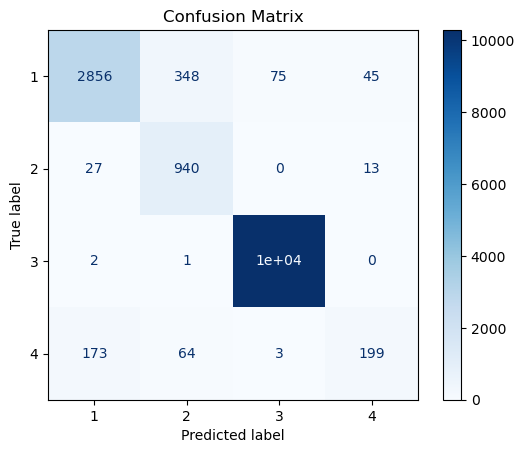

--- Core Classification Metrics for SVC (RBF) ---
Accuracy:  0.6843
Precision: 0.4683
Recall:    0.6843
F1-Score:  0.5561
Confusion Matrix Array:
 [[    0     0  3324     0]
 [    0     0   980     0]
 [    0     0 10283     0]
 [    0     0   439     0]]
--- Core Classification Metrics for SVC (Poly) ---
Accuracy:  0.6843
Precision: 0.4683
Recall:    0.6843
F1-Score:  0.5561
Confusion Matrix Array:
 [[    0     0  3324     0]
 [    0     0   980     0]
 [    0     0 10283     0]
 [    0     0   439     0]]
--- Core Classification Metrics for SVC (Linear) ---
Accuracy:  0.9085
Precision: 0.9181
Recall:    0.9085
F1-Score:  0.8820
Confusion Matrix Array:
 [[ 3214    15    95     0]
 [  877   101     2     0]
 [    2     0 10281     0]
 [  369    11     4    55]]
--- Core Classification Metrics for KNN ---
Accuracy:  0.9757
Precision: 0.9753
Recall:    0.9757
F1-Score:  0.9753
Confusion Matrix Array:
 [[ 3137    51    93    43]
 [   46   927     1     6]
 [   11     7 10264     1]
 [   7

/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


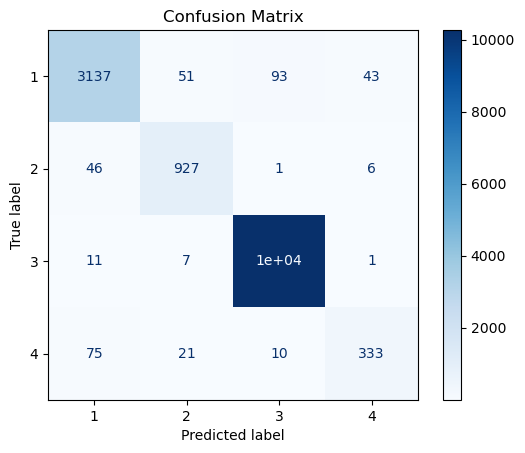

--- Core Classification Metrics for Naive Bayes ---
Accuracy:  0.9448
Precision: 0.9441
Recall:    0.9448
F1-Score:  0.9412
Confusion Matrix Array:
 [[ 3097    53   129    45]
 [  367   594     8    11]
 [    2     0 10281     0]
 [  190    14    10   225]]


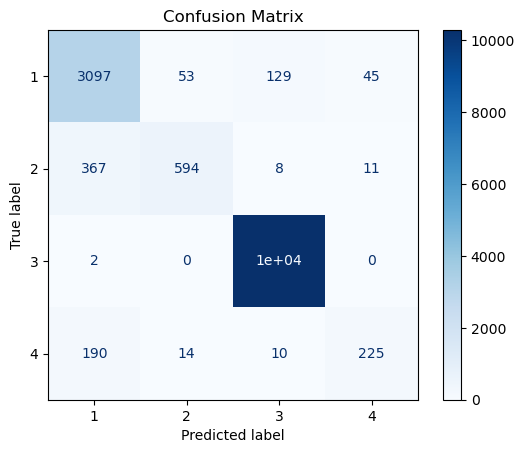

--- Core Classification Metrics for LDA---
Accuracy:  0.9106
Precision: 0.9112
Recall:    0.9106
F1-Score:  0.8879
Confusion Matrix Array:
 [[ 3197    53    72     2]
 [  856   122     0     2]
 [    2     1 10280     0]
 [  346     9     0    84]]


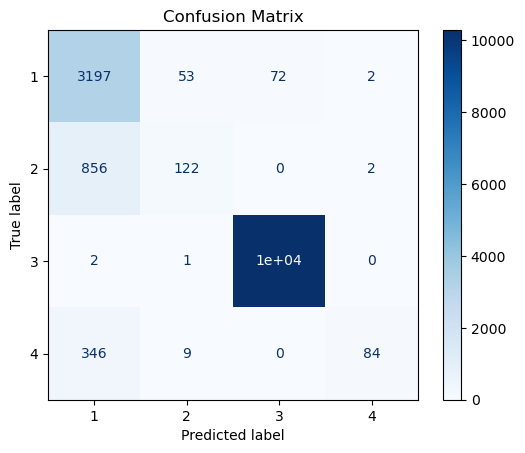

In [60]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 3. Evaluation:
#      ▪ Evaluate the performance of all classifiers on the test set using the following metrics:
#           ▪ Accuracy
#           ▪ Precision
#           ▪ Recall
#           ▪ F1-Score
#      ▪ Generate a confusion matrix for each classifier.

print("--- Core Classification Metrics for Bayes Theorem ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_bayes):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_bayes, average='weighted'):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_bayes, average='weighted'):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_bayes, average='weighted'):.4f}")

cm = confusion_matrix(y_test, y_pred_bayes)

print("Confusion Matrix Array:\n", cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.unique(y_test))
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.show()


print("--- Core Classification Metrics for SVC (RBF) ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_svm):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_svm, average='weighted'):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_svm, average='weighted'):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_svm, average='weighted'):.4f}")

cm = confusion_matrix(y_test, y_pred_svm)

print("Confusion Matrix Array:\n", cm)

print("--- Core Classification Metrics for SVC (Poly) ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_svm_poly):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_svm_poly, average='weighted'):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_svm_poly, average='weighted'):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_svm_poly, average='weighted'):.4f}")

cm = confusion_matrix(y_test, y_pred_svm_poly)

print("Confusion Matrix Array:\n", cm)

print("--- Core Classification Metrics for SVC (Linear) ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_svm_linear):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_svm_linear, average='weighted'):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_svm_linear, average='weighted'):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_svm_linear, average='weighted'):.4f}")

cm = confusion_matrix(y_test, y_pred_svm_linear)

print("Confusion Matrix Array:\n", cm)

print("--- Core Classification Metrics for KNN ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_knn):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_knn, average='weighted'):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_knn, average='weighted'):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_knn, average='weighted'):.4f}")

cm = confusion_matrix(y_test, y_pred_knn)

print("Confusion Matrix Array:\n", cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.unique(y_test))
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.show()


print("--- Core Classification Metrics for Naive Bayes ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_gnb):.4f}")
print(f"Precision: {precision_score(y_test,y_pred_gnb, average='weighted'):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_gnb, average='weighted'):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_gnb, average='weighted'):.4f}")

cm = confusion_matrix(y_test, y_pred_gnb)

print("Confusion Matrix Array:\n", cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.unique(y_test))
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.show()


print("--- Core Classification Metrics for LDA---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_lda):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_lda, average='weighted'):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_lda, average='weighted'):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_lda, average='weighted'):.4f}")

cm = confusion_matrix(y_test, y_pred_lda)

print("Confusion Matrix Array:\n", cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.unique(y_test))
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.show()

print("--- Core Classification Metrics for KDA (RBF) ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_kda):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_kda, average='weighted'):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_kda, average='weighted'):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_kda, average='weighted'):.4f}")

cm = confusion_matrix(y_test, y_pred_kda)

print("Confusion Matrix Array:\n", cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.unique(y_test))
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.show()

print("--- Core Classification Metrics for KDA (Poly) ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_kda_poly):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_kda_poly, average='weighted'):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_kda_poly, average='weighted'):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_kda_poly, average='weighted'):.4f}")

cm = confusion_matrix(y_test, y_pred_kda_poly)

print("Confusion Matrix Array:\n", cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.unique(y_test))
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.show()


In [8]:
from sklearn.preprocessing import StandardScaler
# Part 3: Dimensionality Reduction Using PCA
#     1. Principal Component Analysis (PCA):

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train) 
x_test_scaled = scaler.transform(x_test)
           # o Apply PCA to the dataset to reduce its dimensionality.

pca = PCA(n_components=0.95)

           # o Choose the number of components based on the explained variance ratio (e.g., retain 95% of the variance).

x_train_pca = pca.fit_transform(x_train_scaled)
x_test_pca = pca.transform(x_test_scaled)

           # o Visualize the first two principal components.
print(x_train)
print(f"Original number of features: {x_train.shape[1]}")
print(f"Reduced number of features: {x_test_pca.shape[1]}")
print(f"Total variance retained: {np.sum(pca.explained_variance_ratio_):.2%}")


[[ 1.0694e+00  3.2153e-02 -1.8473e-01 ... -5.6000e+01  4.9164e+00
   9.2075e+02]
 [ 1.1397e+00  1.8143e-01 -2.2806e-03 ... -5.6000e+01  4.3274e+00
   9.2325e+02]
 [ 9.0520e-01 -1.2861e-01 -1.9613e-01 ... -4.6500e+01  1.4527e+00
   9.2175e+02]
 ...
 [ 1.3132e-01  3.7665e-01 -1.0286e+00 ... -5.9500e+01  5.8844e+00
   9.2325e+02]
 [ 1.1749e+00  9.1865e-03 -8.2102e-02 ... -5.7000e+01  6.1620e+00
   9.2575e+02]
 [ 3.5411e-01  2.3885e-01 -9.9434e-01 ... -4.8000e+01  2.8992e-01
   9.2025e+02]]
Original number of features: 7
Reduced number of features: 6
Total variance retained: 98.39%


In [12]:
#     2. Kernel PCA (Optional):

           # o Experiment with Kernel PCA using different kernels (linear, RBF, polynomial) and visualize the results.




    

In [13]:
# Part 4: Classification on the PCA-Reduced Dataset
# Now, apply the same classifiers used in Part 2 to the PCA-reduced dataset:

# 1. Bayesian Classifier (from scratch):
#      o Apply the Bayesian Classifier you built from scratch to the PCA-reduced data.

model = bayes_train(x_train_pca, y_train)
y_pred_pca_bayes = bayes_predict(x_test_pca, model)


In [45]:
# 2. Other Classifiers (using scikit-learn):
#     o Apply the following classifiers on the PCA-reduced dataset:

#          ▪ Linear SVM and Kernel SVM.

svm = SVC()
svm.fit(x_train_pca, y_train)
y_pred_pca_svm = svm.predict(x_test_pca)


In [63]:
svm_poly = SVC(kernel='poly')
svm_poly.fit(x_train_pca, y_train)
y_pred_pca_svm_poly = svm_poly.predict(x_test_pca)

In [64]:
svm_linear = LinearSVC()
svm_linear.fit(x_train_pca, y_train)
y_pred_pca_svm_linear = svm_linear.predict(x_test_pca)

In [14]:
#          ▪ k-Nearest Neighbors (KNN).

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(x_train_pca, y_train)
y_pred_pca_knn = knn.predict(x_test_pca)



In [15]:
#          ▪ Naive Bayes.

gnb = GaussianNB()
y_pred_pca_gnb = gnb.fit(x_train_pca, y_train).predict(x_test_pca)
print("Number of mislabeled points out of a total %d points : %d" % (x_test_pca.shape[0], (y_test != y_pred_pca_gnb).sum()))



Number of mislabeled points out of a total 15026 points : 1423


In [42]:
#          ▪ Linear Discriminant Analysis (LDA).

lda = LinearDiscriminantAnalysis()
lda.fit(x_train_pca, y_train)
print(lda.predict(x_test_pca))
y_pred_pca_lda = lda.predict(x_test_pca)


[3 3 3 ... 3 3 3]


In [77]:
#          ▪ Kernel Discriminant Analysis (KDA).

# I am using Nystroem because creating a kernel directly causes a memory overload error/crash

kda_safeguard_pipeline = Pipeline([
    ('kernel_approx', Nystroem(kernel='rbf', gamma=0.1, n_components=1000,)),
    ('lda', LinearDiscriminantAnalysis())
])


kda_safeguard_pipeline.fit(x_train_pca, y_train)
y_pred_pca_kda = kda_safeguard_pipeline.predict(x_test_pca)

print("--- Core Classification Metrics for PCA KDA (RBF) ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_pca_kda):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_pca_kda, average='weighted'):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_pca_kda, average='weighted'):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_pca_kda, average='weighted'):.4f}")


--- Core Classification Metrics for PCA KDA (RBF) ---
Accuracy:  0.9740
Precision: 0.9732
Recall:    0.9740
F1-Score:  0.9730


In [78]:
kda_safeguard_pipeline = Pipeline([
    ('kernel_approx', Nystroem(kernel='poly', gamma=0.1, n_components=1000,)),
    ('lda', LinearDiscriminantAnalysis())
])


kda_safeguard_pipeline.fit(x_train_pca, y_train)
y_pred_pca_kda_poly = kda_safeguard_pipeline.predict(x_test_pca)

print("--- Core Classification Metrics for PCA KDA (Poly) ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_pca_kda_poly):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_pca_kda_poly, average='weighted'):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_pca_kda_poly, average='weighted'):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_pca_kda_poly, average='weighted'):.4f}")

--- Core Classification Metrics for PCA KDA (Poly) ---
Accuracy:  0.9628
Precision: 0.9618
Recall:    0.9628
F1-Score:  0.9610


In [66]:
# 3. Evaluation:

#     o Evaluate the classifiers again using the same metrics (accuracy, precision, recall, F1-score).

#     o Compare their performance with and without PCA.
# PCA vastly improved SVM (RBF) and either slightly increased or slightly decreased the rest of the classifier

print("--- Core Classification Metrics of PCA Bayes Theorem ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_pca_bayes):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_pca_bayes, average='weighted'):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_pca_bayes, average='weighted'):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_pca_bayes, average='weighted'):.4f}")

print("--- Core Classification Metrics of PCA SVM (RBF) ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_pca_svm):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_pca_svm, average='weighted'):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_pca_svm, average='weighted'):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_pca_svm, average='weighted'):.4f}")

print("--- Core Classification Metrics of PCA SVM (Poly) ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_pca_svm_poly):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_pca_svm_poly, average='weighted'):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_pca_svm_poly, average='weighted'):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_pca_svm_poly, average='weighted'):.4f}")

print("--- Core Classification Metrics of PCA SVM (Linear) ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_pca_svm_linear):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_pca_svm_linear, average='weighted'):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_pca_svm_linear, average='weighted'):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_pca_svm_linear, average='weighted'):.4f}")

print("--- Core Classification Metrics of PCA KNN ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_pca_knn):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_pca_knn, average='weighted'):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_pca_knn, average='weighted'):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_pca_knn, average='weighted'):.4f}")

print("--- Core Classification Metrics of PCA Naive Bayes ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_pca_gnb):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_pca_gnb, average='weighted'):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_pca_gnb, average='weighted'):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_pca_gnb, average='weighted'):.4f}")

print("--- Core Classification Metrics of PCA LDA ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_pca_lda):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_pca_lda, average='weighted'):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_pca_lda, average='weighted'):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_pca_lda, average='weighted'):.4f}")

print("--- Core Classification Metrics for PCA KDA (RBF) ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_pca_kda):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_pca_kda, average='weighted'):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_pca_kda, average='weighted'):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_pca_kda, average='weighted'):.4f}")

print("--- Core Classification Metrics for PCA KDA (Poly) ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_pca_kda_poly):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_pca_kda_poly, average='weighted'):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_pca_kda_poly, average='weighted'):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_pca_kda_poly, average='weighted'):.4f}")



--- Core Classification Metrics of PCA Bayes Theorem ---
Accuracy:  0.9453
Precision: 0.9496
Recall:    0.9453
F1-Score:  0.9447
--- Core Classification Metrics of PCA SVM (RBF) ---
Accuracy:  0.9714
Precision: 0.9719
Recall:    0.9714
F1-Score:  0.9694
--- Core Classification Metrics of PCA SVM (Poly) ---
Accuracy:  0.9634
Precision: 0.9635
Recall:    0.9634
F1-Score:  0.9613
--- Core Classification Metrics of PCA SVM (Linear) ---
Accuracy:  0.8966
Precision: 0.8564
Recall:    0.8966
F1-Score:  0.8617
--- Core Classification Metrics of PCA KNN ---
Accuracy:  0.9825
Precision: 0.9823
Recall:    0.9825
F1-Score:  0.9822
--- Core Classification Metrics of PCA Naive Bayes ---
Accuracy:  0.9053
Precision: 0.9155
Recall:    0.9053
F1-Score:  0.8789
--- Core Classification Metrics of PCA LDA ---
Accuracy:  0.8946
Precision: 0.8854
Recall:    0.8946
F1-Score:  0.8721


In [84]:
# Part 5: Performance Comparison
#     1. Evaluation:
#          o Create a summary table comparing the performance of all classifiers on the entire dataset and the PCA-reduced dataset.
# Define the models in a dictionary

classes = {
    "Classifier": [
        "Bayes Theorem",
        "Support Vector Machine (SVM) (RBF)",
        "Support Vector Machine (SVM) (Poly)",
        "Support Vector Machine (SVM) (Linear)",
        "K-Nearest Neighbors (KNN)",
        "Naive Bayes",
        "Linear Discriminant Analysis (LDA)",
        "Kernel Discriminant Analysis (KDA) (RBF)",
        "Kernel Discriminant Analysis (KDA) (Poly)",
        "PCA Bayes Theorem",
        "PCA Support Vector Machine (SVM) (RBF)",
        "PCA Support Vector Machine (SVM) (Poly)",
        "PCA Support Vector Machine (SVM) (Linear)",
        "PCA K-Nearest Neighbors (KNN)",
        "PCA Naive Bayes",
        "PCA Linear Discriminant Analysis (LDA)",
        "PCA Kernel Discriminant Analysis (KDA) (RBF)",
        "PCA Kernel Discriminant Analysis (KDA) (Poly)",
    ],
    "Accuracy": [accuracy_score(y_test, y_pred_bayes), 
                 accuracy_score(y_test, y_pred_svm), accuracy_score(y_test, y_pred_svm_poly), accuracy_score(y_test, y_pred_svm_linear), 
                 accuracy_score(y_test, y_pred_knn), accuracy_score(y_test, y_pred_gnb), accuracy_score(y_test, y_pred_lda),
                 accuracy_score(y_test, y_pred_kda), accuracy_score(y_test, y_pred_kda_poly),
                 accuracy_score(y_test, y_pred_pca_bayes), 
                 accuracy_score(y_test, y_pred_pca_svm), accuracy_score(y_test, y_pred_pca_svm_poly), accuracy_score(y_test, y_pred_pca_svm_linear), 
                 accuracy_score(y_test, y_pred_pca_knn), accuracy_score(y_test, y_pred_pca_gnb), accuracy_score(y_test, y_pred_pca_lda),
                 accuracy_score(y_test, y_pred_pca_kda), accuracy_score(y_test, y_pred_pca_kda_poly)],
    
    "Precision": [precision_score(y_test, y_pred_bayes, average='weighted'), 
                  precision_score(y_test, y_pred_svm, average='weighted'), precision_score(y_test, y_pred_svm_poly, average='weighted'), precision_score(y_test, y_pred_svm_linear, average='weighted'), 
                  precision_score(y_test, y_pred_knn, average='weighted'), precision_score(y_test, y_pred_gnb, average='weighted'), precision_score(y_test, y_pred_lda, average='weighted'),
                  precision_score(y_test, y_pred_kda, average='weighted'), precision_score(y_test, y_pred_kda_poly, average='weighted'),
                  precision_score(y_test, y_pred_pca_bayes, average='weighted'), 
                  precision_score(y_test, y_pred_pca_svm, average='weighted'), precision_score(y_test, y_pred_pca_svm_poly, average='weighted'), precision_score(y_test, y_pred_pca_svm_linear, average='weighted'), 
                  precision_score(y_test, y_pred_pca_knn, average='weighted'), precision_score(y_test, y_pred_pca_gnb, average='weighted'), precision_score(y_test, y_pred_pca_lda, average='weighted'),
                  precision_score(y_test, y_pred_pca_kda, average='weighted'), precision_score(y_test, y_pred_pca_kda_poly, average='weighted')],
    
    "Recall": [recall_score(y_test, y_pred_bayes, average='weighted'), 
               recall_score(y_test, y_pred_svm, average='weighted'), recall_score(y_test, y_pred_svm_poly, average='weighted'), recall_score(y_test, y_pred_svm_linear, average='weighted'),  
               recall_score(y_test, y_pred_knn, average='weighted'), recall_score(y_test, y_pred_gnb, average='weighted'), recall_score(y_test, y_pred_lda, average='weighted'),
               recall_score(y_test, y_pred_kda, average='weighted'), recall_score(y_test, y_pred_kda_poly, average='weighted'),
               recall_score(y_test, y_pred_pca_bayes, average='weighted'), 
               recall_score(y_test, y_pred_pca_svm, average='weighted'), recall_score(y_test, y_pred_pca_svm_poly, average='weighted'), recall_score(y_test, y_pred_pca_svm_linear, average='weighted'),
               recall_score(y_test, y_pred_pca_knn, average='weighted'), recall_score(y_test, y_pred_pca_gnb, average='weighted'), recall_score(y_test, y_pred_pca_lda, average='weighted'),
               recall_score(y_test, y_pred_pca_kda, average='weighted'), recall_score(y_test, y_pred_pca_kda_poly, average='weighted')],
    
    "F1-Score": [f1_score(y_test, y_pred_bayes, average='weighted'), 
                 f1_score(y_test, y_pred_svm, average='weighted'), f1_score(y_test, y_pred_svm_poly, average='weighted'), f1_score(y_test, y_pred_svm_linear, average='weighted'),
                 f1_score(y_test, y_pred_knn, average='weighted'), f1_score(y_test, y_pred_gnb, average='weighted'), f1_score(y_test, y_pred_lda, average='weighted'),
                 f1_score(y_test, y_pred_kda, average='weighted'), f1_score(y_test, y_pred_kda_poly, average='weighted'),
                 f1_score(y_test, y_pred_pca_bayes, average='weighted'), 
                 f1_score(y_test, y_pred_pca_svm, average='weighted'), f1_score(y_test, y_pred_pca_svm_poly, average='weighted'), f1_score(y_test, y_pred_pca_svm_linear, average='weighted'),
                 f1_score(y_test, y_pred_pca_knn, average='weighted'), f1_score(y_test, y_pred_pca_gnb, average='weighted'), f1_score(y_test, y_pred_pca_lda, average='weighted'),
                 f1_score(y_test, y_pred_pca_kda, average='weighted'), f1_score(y_test, y_pred_pca_kda_poly, average='weighted')],
}

df = pd.DataFrame(classes)

print(df.to_markdown(index=False))

/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


| Classifier                                    |   Accuracy |   Precision |   Recall |   F1-Score |
|:----------------------------------------------|-----------:|------------:|---------:|-----------:|
| Bayes Theorem                                 |   0.95002  |    0.953732 | 0.95002  |   0.948918 |
| Support Vector Machine (SVM) (RBF)            |   0.684347 |    0.468331 | 0.684347 |   0.556098 |
| Support Vector Machine (SVM) (Poly)           |   0.963397 |    0.963545 | 0.963397 |   0.961306 |
| Support Vector Machine (SVM) (Linear)         |   0.896579 |    0.856419 | 0.896579 |   0.861699 |
| K-Nearest Neighbors (KNN)                     |   0.975709 |    0.975267 | 0.975709 |   0.975341 |
| Naive Bayes                                   |   0.944829 |    0.944096 | 0.944829 |   0.941206 |
| Linear Discriminant Analysis (LDA)            |   0.910622 |    0.911183 | 0.910622 |   0.887935 |
| Kernel Discriminant Analysis (KDA) (RBF)      |   0.970651 |    0.969438 | 0.970651 |   0

In [85]:
#     2. Comparison and Discussion:
#          o Compare the Bayesian classifier built from scratch to its scikit-learn counterparts.
# The Bayesian Classifier gives higher scores for both regular data and PCA, than Naive Bayes scikit-learn counterpart.
# I believe it is due to the very large dataset that works better with the Bayesian Classifier than Naive Bayes.

#          o Analyze the impact of PCA on the classifiers’ performance.
# PCA has helped reduce computation time slightly on some classifiers and significantly on a SVM. 
# SVM (RBF) saw significant improved performance when using PCA, but other classifiers saw slightly higher or slightly lower scores.

#          o Discuss the effect of using different kernels in SVM and KDA.
# Different kernels results in different scores in SVM (regular data), with (Poly) having higher scores , with (Linear} having lower scores, and (RBF) having even lower.
# Different kernels results in different scores in SVM (PCA), with (RBF) having higher scores , with (Poly} having lower scores, and (Linear) having even lower.
# Different kernels results in relatively high scores for KDA in both (RBF) and (Poly), with (RBF) having slightly higher scores.
# KDA (PCA) yields slightly higher scores than KDA (regular data)
